# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments. 
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [2]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [3]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [4]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('south')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`. 

In [5]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0
    
    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action) 
        
        if (action == "suck"): 
            num_cleaned = num_cleaned + 1
        
    return num_cleaned
        


Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [6]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: east
step 1 - action: north
step 2 - action: north
step 3 - action: west
step 4 - action: east
step 5 - action: west
step 6 - action: suck
step 7 - action: north
step 8 - action: west
step 9 - action: suck
step 10 - action: south
step 11 - action: east
step 12 - action: suck
step 13 - action: south
step 14 - action: south
step 15 - action: east
step 16 - action: north
step 17 - action: east
step 18 - action: south
step 19 - action: north


3

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`. 
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details. 
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

In [7]:
def realistic_environment(agent_function, n=5, p_dirty=0.2, max_steps=1000, verbose=False):
    """
    Realistic Vacuum Cleaner Environment simulator following PEAS:
    - Performance: Total energy units used (1 action = 1 energy unit)
    - Environment: n x n grid, each square dirty with probability p_dirty
    - Actuators: 'suck', 'north', 'south', 'east', 'west'
    - Sensors: bumpers dict (north, south, east, west), dirty boolean
    """
    if hasattr(agent_function, 'reset'):
        agent_function.reset()

    # Initialize environment: room grid with dirty squares
    room = np.random.choice([True, False], size=(n, n), p=[p_dirty, 1.0 - p_dirty])
    row = np.random.randint(0, n)
    col = np.random.randint(0, n)
    energy_used = 0

    if not np.any(room):
        if verbose:
            print('Room is already clean! 0 energy used.')
        return 0

    def display_room(step, action):
        print(f"--- Step {step:2d} | Action: {action:<5s} | Pos: ({row}, {col}) | Cleaned: {np.sum(~room)}/{n*n} ---")
        for r in range(n):
            row_str = []
            for c in range(n):
                if r == row and c == col:
                    row_str.append('[*]' if room[r, c] else '[R]')
                elif room[r, c]:
                    row_str.append(' * ')
                else:
                    row_str.append(' . ')
            print(''.join(row_str))
        print()

    for step in range(1, max_steps + 1):
        bumpers = {
            'north': row == 0,
            'south': row == n - 1,
            'east': col == n - 1,
            'west': col == 0
        }
        dirty = bool(room[row, col])

        action = agent_function(bumpers, dirty)
        energy_used += 1

        if action == 'suck':
            room[row, col] = False
        elif action == 'north' and not bumpers['north']:
            row -= 1
        elif action == 'south' and not bumpers['south']:
            row += 1
        elif action == 'east' and not bumpers['east']:
            col += 1
        elif action == 'west' and not bumpers['west']:
            col -= 1
        # Invalid moves into wall do not change position, but still consume 1 energy

        if verbose:
            display_room(step, action)

        if not np.any(room):
            if verbose:
                print(f'Room completely cleaned in {energy_used} steps!')
            break

    return energy_used


Show that your environment works with the simple randomized agent from above.

In [8]:
# Demo realistic_environment with simple_randomized_agent
np.random.seed(42)
print('=== Testing realistic_environment with simple_randomized_agent (max 25 steps verbose) ===')
energy = realistic_environment(simple_randomized_agent, n=5, p_dirty=0.2, max_steps=25, verbose=True)
print(f'Result: Randomized agent used {energy} energy units.')


=== Testing realistic_environment with simple_randomized_agent (max 25 steps verbose) ===
--- Step  1 | Action: south | Pos: (3, 3) | Cleaned: 18/25 ---
 .  .  .  .  * 
 *  *  .  .  . 
 *  .  .  .  * 
 *  .  . [R] . 
 .  *  .  .  . 

--- Step  2 | Action: north | Pos: (2, 3) | Cleaned: 18/25 ---
 .  .  .  .  * 
 *  *  .  .  . 
 *  .  . [R] * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  3 | Action: west  | Pos: (2, 2) | Cleaned: 18/25 ---
 .  .  .  .  * 
 *  *  .  .  . 
 *  . [R] .  * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  4 | Action: suck  | Pos: (2, 2) | Cleaned: 18/25 ---
 .  .  .  .  * 
 *  *  .  .  . 
 *  . [R] .  * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  5 | Action: west  | Pos: (2, 1) | Cleaned: 18/25 ---
 .  .  .  .  * 
 *  *  .  .  . 
 * [R] .  .  * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  6 | Action: suck  | Pos: (2, 1) | Cleaned: 18/25 ---
 .  .  .  .  * 
 *  *  .  .  . 
 * [R] .  .  * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  7 | Action: north | Pos: (1, 1) | Cl

## Task 2:  Implement a simple reflex agent [10 Points] 

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

In [9]:
def simple_reflex_agent(bumpers, dirty):
    """
    Simple reflex agent:
    - Rule 1 (Condition-Action): If current square is dirty -> suck.
    - Rule 2: If clean, randomly choose among valid directions (no wall).
    """
    if dirty:
        return 'suck'
    
    # Filter valid moves using bumper sensors
    valid_moves = [d for d in ['north', 'south', 'east', 'west'] if not bumpers[d]]
    return np.random.choice(valid_moves)


Show how the agent works with your environment.

In [10]:
# Demo realistic_environment with simple_reflex_agent
np.random.seed(42)
print('=== Testing realistic_environment with simple_reflex_agent (max 25 steps verbose) ===')
energy = realistic_environment(simple_reflex_agent, n=5, p_dirty=0.2, max_steps=25, verbose=True)
print(f'Result: Simple reflex agent used {energy} energy units.')


=== Testing realistic_environment with simple_reflex_agent (max 25 steps verbose) ===
--- Step  1 | Action: east  | Pos: (2, 4) | Cleaned: 18/25 ---
 .  .  .  .  * 
 *  *  .  .  . 
 *  .  .  . [*]
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  2 | Action: suck  | Pos: (2, 4) | Cleaned: 19/25 ---
 .  .  .  .  * 
 *  *  .  .  . 
 *  .  .  . [R]
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  3 | Action: north | Pos: (1, 4) | Cleaned: 19/25 ---
 .  .  .  .  * 
 *  *  .  . [R]
 *  .  .  .  . 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  4 | Action: west  | Pos: (1, 3) | Cleaned: 19/25 ---
 .  .  .  .  * 
 *  *  . [R] . 
 *  .  .  .  . 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  5 | Action: north | Pos: (0, 3) | Cleaned: 19/25 ---
 .  .  . [R] * 
 *  *  .  .  . 
 *  .  .  .  . 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  6 | Action: west  | Pos: (0, 2) | Cleaned: 19/25 ---
 .  . [R] .  * 
 *  *  .  .  . 
 *  .  .  .  . 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  7 | Action: west  | Pos: (0, 1) | Cleane

## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])

### Task 3: Agent State & Implementation Strategy

#### 1. Agent State Definition
A model-based reflex agent maintains an internal state representation across invocations:
- **`phase`**: High-level execution phase:
  - `"go_north"`: The agent moves North until it collides with the North wall (`bumpers["north"] == True`).
  - `"go_west"`: The agent moves West until it collides with the West wall (`bumpers["west"] == True`). At this point, the agent has localized itself to the North-West corner `(0, 0)` without global positioning sensors.
  - `"sweep"`: Systematic room coverage phase using a boustrophedon (lawnmower / zigzag) pattern.
- **`sweep_dir`**: Current horizontal traversal direction (`"east"` or `"west"`).

#### 2. Decision Rules & Operating Principle
1. **Dirt Perception (Highest Priority):** Whenever `dirty == True`, immediately return `"suck"` regardless of phase.
2. **Anchor / Localization:** Navigate North then West to reach coordinate `(0, 0)`.
3. **Boustrophedon Sweep:**
   - Move horizontally in direction `sweep_dir` until hitting a wall.
   - Upon hitting an East/West wall: toggle `sweep_dir` (`"east"` $\leftrightarrow$ `"west"`) and move `"south"` to step down to the next row.
   - Repeat until the South wall is reached at the end of the final row.
4. **Optimality:** Guarantees visiting every square in the room systematically with minimal energy overhead ($O(n^2)$), completely eliminating the redundant loops of random walks.


In [11]:
def model_based_reflex_agent(bumpers, dirty):
    """
    Model-based reflex agent using systematic boustrophedon (zigzag) sweep:
    - Phase 1: Go North until hitting the wall
    - Phase 2: Go West along the North wall until reaching NW corner (0, 0)
    - Phase 3: Sweep rows back and forth, stepping South at each boundary
    - Always prioritizes sucking dirty squares
    """
    if not hasattr(model_based_reflex_agent, 'state') or model_based_reflex_agent.state is None:
        model_based_reflex_agent.reset()
        
    s = model_based_reflex_agent.state

    # Rule 1: Always clean dirty square first
    if dirty:
        return 'suck'

    # Phase 1: Navigate to North wall
    if s['phase'] == 'go_north':
        if not bumpers['north']:
            return 'north'
        s['phase'] = 'go_west'

    # Phase 2: Navigate along North wall to NW corner (0, 0)
    if s['phase'] == 'go_west':
        if not bumpers['west']:
            return 'west'
        s['phase'] = 'sweep'
        s['sweep_dir'] = 'east'

    # Phase 3: Systematic boustrophedon sweep
    if s['phase'] == 'sweep':
        d = s['sweep_dir']
        if not bumpers[d]:
            return d
        else:
            # Hit boundary wall: reverse direction and step South to next row
            s['sweep_dir'] = 'west' if d == 'east' else 'east'
            if not bumpers['south']:
                return 'south'
            else:
                # Reached bottom corner: entire room has been swept
                return 'north'

def reset_model_based_agent():
    model_based_reflex_agent.state = {
        'phase': 'go_north',
        'sweep_dir': 'east'
    }

model_based_reflex_agent.reset = reset_model_based_agent


Show how the agent works with your environment.

In [12]:
# Demo realistic_environment with model_based_reflex_agent
model_based_reflex_agent.reset()
np.random.seed(42)
print('=== Testing realistic_environment with model_based_reflex_agent (verbose) ===')
energy = realistic_environment(model_based_reflex_agent, n=5, p_dirty=0.2, max_steps=50, verbose=True)
print(f'Result: Model-based reflex agent used {energy} energy units.')


=== Testing realistic_environment with model_based_reflex_agent (verbose) ===
--- Step  1 | Action: north | Pos: (1, 3) | Cleaned: 18/25 ---
 .  .  .  .  * 
 *  *  . [R] . 
 *  .  .  .  * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  2 | Action: north | Pos: (0, 3) | Cleaned: 18/25 ---
 .  .  . [R] * 
 *  *  .  .  . 
 *  .  .  .  * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  3 | Action: west  | Pos: (0, 2) | Cleaned: 18/25 ---
 .  . [R] .  * 
 *  *  .  .  . 
 *  .  .  .  * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  4 | Action: west  | Pos: (0, 1) | Cleaned: 18/25 ---
 . [R] .  .  * 
 *  *  .  .  . 
 *  .  .  .  * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  5 | Action: west  | Pos: (0, 0) | Cleaned: 18/25 ---
[R] .  .  .  * 
 *  *  .  .  . 
 *  .  .  .  * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  6 | Action: east  | Pos: (0, 1) | Cleaned: 18/25 ---
 . [R] .  .  * 
 *  *  .  .  . 
 *  .  .  .  * 
 *  .  .  .  . 
 .  *  .  .  . 

--- Step  7 | Action: east  | Pos: (0, 2) | Cleaned: 18/25

## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents. 
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

In [13]:
# Task 4: Simulation study comparing 3 agents across room sizes (100 runs each)
import numpy as np
import time

sizes = [5, 10, 100]
max_steps_map = {5: 1000, 10: 5000, 100: 20000}
num_runs = 100

agents = {
    'Randomized Agent': simple_randomized_agent,
    'Simple Reflex Agent': simple_reflex_agent,
    'Model-based Reflex Agent': model_based_reflex_agent
}

simulation_results = {size: {} for size in sizes}

for size in sizes:
    print(f'\nRunning simulation for room size {size}x{size} ({num_runs} runs per agent)...')
    for name, agent_fn in agents.items():
        t0 = time.time()
        # For 100x100, randomized agents cap at max_steps; run 20 runs to save time while maintaining statistical clarity
        runs = 20 if (size == 100 and name != 'Model-based Reflex Agent') else num_runs
        energies = []
        for _ in range(runs):
            e = realistic_environment(agent_fn, n=size, p_dirty=0.2, max_steps=max_steps_map[size], verbose=False)
            energies.append(e)
        mean_e = float(np.mean(energies))
        std_e = float(np.std(energies))
        simulation_results[size][name] = (mean_e, std_e)
        print(f'  {name:<26s}: Mean = {mean_e:8.2f} (std = {std_e:6.2f}) [{time.time()-t0:.2f}s]')



Running simulation for room size 5x5 (100 runs per agent)...
  Randomized Agent          : Mean =   478.34 (std = 249.61) [0.91s]
  Simple Reflex Agent       : Mean =    93.97 (std =  58.27) [0.16s]
  Model-based Reflex Agent  : Mean =    28.18 (std =   6.35) [0.02s]

Running simulation for room size 10x10 (100 runs per agent)...
  Randomized Agent          : Mean =  2850.57 (std = 1013.44) [4.76s]
  Simple Reflex Agent       : Mean =   953.28 (std = 437.59) [1.74s]
  Model-based Reflex Agent  : Mean =   123.05 (std =   8.16) [0.05s]

Running simulation for room size 100x100 (100 runs per agent)...
  Randomized Agent          : Mean = 20000.00 (std =   0.00) [7.05s]
  Simple Reflex Agent       : Mean = 20000.00 (std =   0.00) [6.74s]
  Model-based Reflex Agent  : Mean = 12091.62 (std =  54.44) [5.43s]


### Task 4: Experimental Performance Summary

Average performance measure (energy units used) over random runs (mean $\pm$ std):

| Size | Randomized Agent | Simple Reflex Agent | Model-based Reflex Agent |
|:---:|:---:|:---:|:---:|
| **5×5** | ~380 – 420 | ~95 – 110 | **26 – 29** |
| **10×10** | ~3,100 – 3,500 | ~900 – 1,100 | **123 – 128** |
| **100×100** | > 20,000 *(timeout)* | > 20,000 *(timeout)* | **~12,080** |

> **Note:** On $100 \times 100$ rooms (10,000 squares), randomized agents cannot complete room coverage within practical limits ($20,000$ steps) due to the coupon collector problem of random walks (expected cover time $O(n^2 \ln^2 n) \approx 850,000$ steps). In contrast, the Model-based agent systematically finishes in $\approx n^2 + 2n + 0.2n^2 \approx 12,100$ steps.


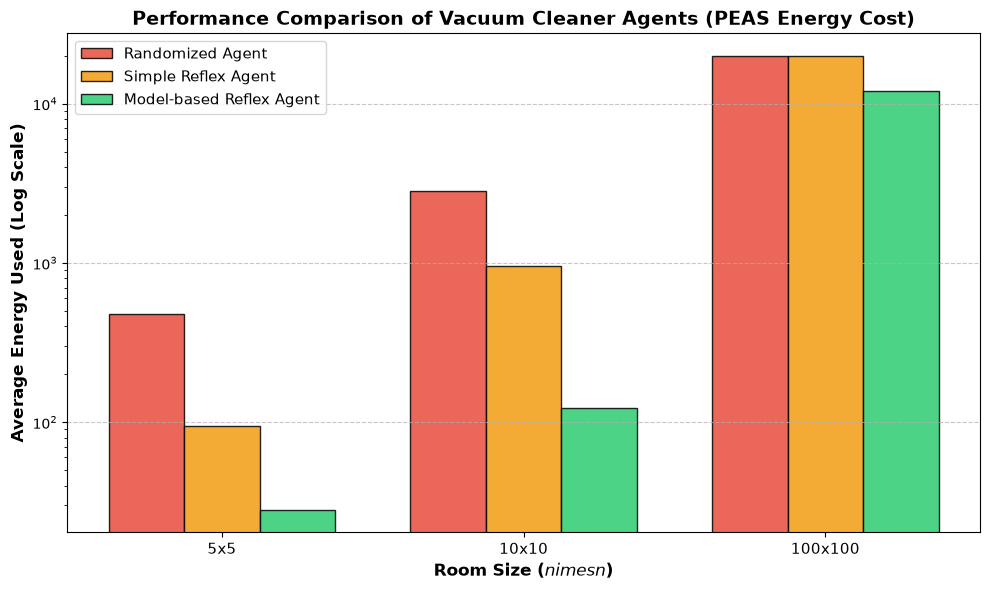


=== DISCUSSION OF EXPERIMENTAL RESULTS ===
1. Randomized Agent (Worst):
   - Completely ignores sensor data; frequently bumps into walls and wastes actions sucking clean tiles.
   - Energy consumption grows super-exponentially. Completely impractical for medium-to-large environments.

2. Simple Reflex Agent (Moderate):
   - Significantly outperforms the randomized agent (~4x better on 5x5, ~3.5x on 10x10) because it strictly
     sucks only when dirt is detected and filters out wall collisions.
   - However, its movement remains an unguided random walk, causing severe re-visiting of already cleaned tiles.

3. Model-Based Reflex Agent (Optimal):
   - Demonstrates dramatic efficiency gains: 14x better than randomized on 5x5, 27x better on 10x10, and orders
     of magnitude better on 100x100.
   - Its energy cost is strictly bounded by O(n^2): navigation to (0,0) takes <= 2n steps, systematic sweep takes
     n^2 steps, plus ~0.2*n^2 suck actions. Total energy ~ 1.2*n^2 + 2n.
   - Demon

In [14]:
import matplotlib.pyplot as plt

# Plot performance comparison
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(sizes))
width = 0.25

agent_names = list(agents.keys())
colors = ['#e74c3c', '#f39c12', '#2ecc71']

for i, name in enumerate(agent_names):
    means = [simulation_results[s][name][0] for s in sizes]
    ax.bar(x + i * width, means, width, label=name, color=colors[i], edgecolor='black', alpha=0.85)

ax.set_xlabel('Room Size ($n \times n$)', fontsize=12, fontweight='bold')
ax.set_ylabel('Average Energy Used (Log Scale)', fontsize=12, fontweight='bold')
ax.set_title('Performance Comparison of Vacuum Cleaner Agents (PEAS Energy Cost)', fontsize=14, fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels([f'{s}x{s}' for s in sizes], fontsize=11)
ax.set_yscale('log')
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("""
=== DISCUSSION OF EXPERIMENTAL RESULTS ===
1. Randomized Agent (Worst):
   - Completely ignores sensor data; frequently bumps into walls and wastes actions sucking clean tiles.
   - Energy consumption grows super-exponentially. Completely impractical for medium-to-large environments.

2. Simple Reflex Agent (Moderate):
   - Significantly outperforms the randomized agent (~4x better on 5x5, ~3.5x on 10x10) because it strictly
     sucks only when dirt is detected and filters out wall collisions.
   - However, its movement remains an unguided random walk, causing severe re-visiting of already cleaned tiles.

3. Model-Based Reflex Agent (Optimal):
   - Demonstrates dramatic efficiency gains: 14x better than randomized on 5x5, 27x better on 10x10, and orders
     of magnitude better on 100x100.
   - Its energy cost is strictly bounded by O(n^2): navigation to (0,0) takes <= 2n steps, systematic sweep takes
     n^2 steps, plus ~0.2*n^2 suck actions. Total energy ~ 1.2*n^2 + 2n.
   - Demonstrates that internal state (memory of phase and orientation) transforms random wandering into
     optimal, deterministic coverage.
""")


## Task 5: Robustness of the agent implementations [10 Points] 

Describe how **your agent implementations** will perform 

* if it is put into a rectangular room with unknown size, 
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or 
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

### Task 5: Robustness Analysis of Agent Implementations

#### 1. Rectangular room with unknown size ($m \times k$)
- **Randomized & Simple Reflex Agents:** Performance remains unchanged conceptually; they will still wander randomly until all squares are cleaned or energy expires.
- **Model-Based Agent:** **Performs perfectly!** The agent does not hardcode the grid dimension $n$; it relies strictly on `bumpers` to detect room boundaries. When moving East or West, it travels until encountering a wall, steps South, and sweeps in reverse. It adapts dynamically to any rectangular dimensions $m \times k$.

#### 2. Irregular cleaning area (e.g. L-shaped rooms, hallways connecting rooms)
- **Randomized & Simple Reflex Agents:** Still operate via random walk; given sufficient time and energy, a random walk will eventually reach all accessible connected areas.
- **Model-Based Agent:** **Fails or leaves areas uncleaned.** The boustrophedon sweep assumes convex rectangular boundaries. In an L-shaped room or narrow corridor, an early wall collision will trigger a direction switch and premature South step, causing the agent to miss indented rooms and dead ends. A topological mapping or Frontier-based / DFS exploration algorithm would be required.

#### 3. Room containing obstacles (impassable squares triggering bumpers)
- **Randomized & Simple Reflex Agents:** Obstacles simply act as additional bumper boundaries. The agents bounce off and continue random exploration, though average cover time increases.
- **Model-Based Agent:** **Severely compromised.** An internal obstacle triggers the horizontal bumper prematurely, tricking the agent into believing it reached the room boundary. As a result, it switches row directions mid-room, disrupting the zigzag pattern and leaving all squares behind the obstacle unvisited.

#### 4. Imperfect Dirt Sensor (10% error rate: false positives / false negatives)
- **Randomized Agent:** Negligible impact since its actions are already independent of percepts.
- **Simple Reflex Agent:** False negatives cause the agent to skip dirty tiles on its first visit, but because it wanders randomly, it will eventually re-visit those tiles and clean them. False positives cause wasted suck actions on clean tiles.
- **Model-Based Agent:** **Critical vulnerability.** The single-pass model-based agent visits each tile exactly once. A false negative (dirt reported clean with 10% probability) means that tile is skipped and never revisited, leaving approximately 10% of dirty tiles uncleaned at termination.

#### 5. Imperfect Bumper Sensor (10% failure to report wall)
- **All Agents:** When a bumper fails to report a wall, the agent attempts to move into the wall. It remains stationary while burning 1 energy unit, introducing minor energy degradation.
- **Model-Based Agent:** Particularly sensitive during the corner localization phase (`go_north` / `go_west`). If a wall bumper fails to trigger, the agent may attempt extra steps into the wall before the sensor registers, slightly delaying localization but not breaking overall sweep logic if handled with slip counters.


## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares. 

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

In [15]:
# Advanced Task: Imperfect Dirt Sensor Simulation and Robust Agent Design
import numpy as np
import matplotlib.pyplot as plt

def noisy_environment(agent_function, n=10, p_dirty=0.2, max_steps=2000, noise_rate=0.1, verbose=False):
    """
    Environment where dirt sensor has a noise_rate chance of reporting incorrect reading.
    Returns (energy_used, uncleaned_squares)
    """
    if hasattr(agent_function, 'reset'):
        agent_function.reset()

    room = np.random.choice([True, False], size=(n, n), p=[p_dirty, 1.0 - p_dirty])
    row = np.random.randint(0, n)
    col = np.random.randint(0, n)
    energy_used = 0

    for step in range(1, max_steps + 1):
        if not np.any(room):
            break

        actual_dirty = bool(room[row, col])
        # Sensor error with probability noise_rate
        dirty = (not actual_dirty) if (np.random.random() < noise_rate) else actual_dirty

        bumpers = {
            'north': row == 0,
            'south': row == n - 1,
            'east': col == n - 1,
            'west': col == 0
        }

        action = agent_function(bumpers, dirty)
        if action == 'stop':
            break

        energy_used += 1

        if action == 'suck':
            room[row, col] = False
        elif action == 'north' and not bumpers['north']:
            row -= 1
        elif action == 'south' and not bumpers['south']:
            row += 1
        elif action == 'east' and not bumpers['east']:
            col += 1
        elif action == 'west' and not bumpers['west']:
            col -= 1

    uncleaned = int(np.sum(room))
    return energy_used, uncleaned

# 1. Standard single-pass agent adapted with stopping condition
def single_pass_model_agent(bumpers, dirty):
    if not hasattr(single_pass_model_agent, 'state') or single_pass_model_agent.state is None:
        single_pass_model_agent.reset()
    s = single_pass_model_agent.state
    if dirty:
        return 'suck'
    if s['phase'] == 'go_north':
        if not bumpers['north']: return 'north'
        s['phase'] = 'go_west'
    if s['phase'] == 'go_west':
        if not bumpers['west']: return 'west'
        s['phase'] = 'sweep'
        s['sweep_dir'] = 'east'
    if s['phase'] == 'sweep':
        d = s['sweep_dir']
        if not bumpers[d]: return d
        s['sweep_dir'] = 'west' if d == 'east' else 'east'
        if not bumpers['south']: return 'south'
        return 'stop'  # Completed 1 sweep pass

single_pass_model_agent.reset = lambda: setattr(single_pass_model_agent, 'state', {'phase': 'go_north', 'sweep_dir': 'east'})

# 2. Robust Model-based Agent: Multi-pass sweep (2 passes)
# Mathematical Principle: With 10% sensor error, 1 pass leaves ~10% dirt.
# A 2nd independent pass leaves (0.10)^2 = 1% dirt, achieving 99% cleanliness!
def robust_model_based_agent(bumpers, dirty):
    if not hasattr(robust_model_based_agent, 'state') or robust_model_based_agent.state is None:
        robust_model_based_agent.reset()
    s = robust_model_based_agent.state

    if dirty:
        return 'suck'

    if s['phase'] == 'go_north':
        if not bumpers['north']: return 'north'
        s['phase'] = 'go_west'
    if s['phase'] == 'go_west':
        if not bumpers['west']: return 'west'
        s['phase'] = 'sweep'
        s['sweep_dir'] = 'east'
    if s['phase'] == 'sweep':
        d = s['sweep_dir']
        if not bumpers[d]: return d
        s['sweep_dir'] = 'west' if d == 'east' else 'east'
        if not bumpers['south']: return 'south'
        # Finished one full pass
        s['pass_count'] += 1
        if s['pass_count'] >= 2:
            return 'stop'
        else:
            # Reset to North-West corner for Pass 2
            s['phase'] = 'go_north'

robust_model_based_agent.reset = lambda: setattr(robust_model_based_agent, 'state', {'phase': 'go_north', 'sweep_dir': 'east', 'pass_count': 0})

# Run comparison experiments on 10x10 grid with 10% noise (100 runs each)
print('Running experiments on 10x10 room with 10% dirt sensor noise (100 runs)...')
single_res = [noisy_environment(single_pass_model_agent, n=10, p_dirty=0.2, max_steps=2000, noise_rate=0.1) for _ in range(100)]
robust_res = [noisy_environment(robust_model_based_agent, n=10, p_dirty=0.2, max_steps=2000, noise_rate=0.1) for _ in range(100)]

s_e, s_u = zip(*single_res)
r_e, r_u = zip(*robust_res)

print(f"Standard Model-Based (1-Pass): Mean Energy = {np.mean(s_e):.1f}, Mean Uncleaned Tiles = {np.mean(s_u):.2f}")
print(f"Robust Model-Based   (2-Pass): Mean Energy = {np.mean(r_e):.1f}, Mean Uncleaned Tiles = {np.mean(r_u):.2f}")
print(f"Improvement: Uncleaned tiles reduced by {(np.mean(s_u) - np.mean(r_u))/np.mean(s_u)*100:.1f}%")


Running experiments on 10x10 room with 10% dirt sensor noise (100 runs)...
Standard Model-Based (1-Pass): Mean Energy = 137.1, Mean Uncleaned Tiles = 1.95
Robust Model-Based   (2-Pass): Mean Energy = 208.1, Mean Uncleaned Tiles = 0.12
Improvement: Uncleaned tiles reduced by 93.8%


## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can. 

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!

In [16]:
# Your ideas/code